# 🛍️ Customer Segmentation Using Unsupervised Learning

**Practical Exam – Set A | Online Retail II | Customer Segmentation**

In this project, I act as a junior data scientist supporting an e-commerce marketing team. Instead of sending the same promotion to every customer, I will use transaction history to identify groups of customers with similar buying patterns. I will build customer-level **RFM features (Recency, Frequency and Monetary)** and compare K-Means, Agglomerative Hierarchical Clustering and DBSCAN.

> **My approach:** clean the transactions carefully, explore the data, create and prepare RFM features, test the three algorithms, compare their results, and translate the clusters into practical marketing actions.

This notebook follows the practical exam brief and the clustering methods demonstrated in the supplied course/reference materials. I have kept the implementation focused on pandas, NumPy, Matplotlib/Seaborn, scikit-learn and SciPy concepts covered in the course.

## 🧭 Project Roadmap

1. Load, clean and explore the transactions
2. Engineer and preprocess RFM features
3. Find a suitable K for K-Means and profile the clusters
4. Explore Hierarchical Clustering using a dendrogram and linkage comparison
5. Tune DBSCAN and identify its clusters and noise points
6. Compare the algorithms, check K-Means stability and make a business recommendation
7. Save the scaler/model and prepare submission files

In [1]:
# Import the libraries used throughout the project
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import joblib

# A consistent style keeps the figures readable and professional
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
print('Libraries imported successfully. Ready to begin the analysis.')

Libraries imported successfully. Ready to begin the analysis.


## 📂 Step 1 — Dataset Loading & Exploratory Data Analysis

The CSV contains the same information as the Excel version mentioned in the exam brief, but its column names differ slightly. I will standardize the names first so that the rest of the notebook follows the exam terminology.

In [2]:
# Read the dataset. The uploaded file name may differ slightly between sessions.
from pathlib import Path

DATA_CANDIDATES = [
    'online_retail_II(3).csv',
    'online_retail_II(2).csv',
    'online_retail_II.csv',
    'online_retail_II.xlsx'
]
DATA_PATH = next((candidate for candidate in DATA_CANDIDATES if Path(candidate).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        'Dataset not found. Place online_retail_II CSV/XLSX beside this notebook. '
        f'Checked: {DATA_CANDIDATES}'
    )

if DATA_PATH.endswith('.xlsx'):
    raw_df = pd.read_excel(DATA_PATH)
else:
    raw_df = pd.read_csv(DATA_PATH, low_memory=False)

# Rename columns to match the exam brief
raw_df = raw_df.rename(columns={
    'Invoice': 'InvoiceNo',
    'Price': 'UnitPrice',
    'Customer ID': 'CustomerID'
})

print('Dataset loaded from:', DATA_PATH)
print('Dataset shape:', raw_df.shape)
print('\nDataset information:')
raw_df.info()
print('\nFirst 10 rows:')
display(raw_df.head(10))

Dataset loaded from: online_retail_II.csv
Dataset shape: (1067371, 8)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   InvoiceNo    1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   UnitPrice    1067371 non-null  float64
 6   CustomerID   824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB

First 10 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


### 1.1 Load & Filter

The exam asks us to focus on UK customers and remove records that cannot be tied to a customer. I will also remove non-purchase quantities and invalid prices, because these would distort customer spending and order-frequency calculations. I will report the row counts at each stage so the cleaning process is transparent.

In [3]:
# Keep a copy of the original data for country-level context
country_context = raw_df.copy()

uk_df = raw_df[raw_df['Country'] == 'United Kingdom'].copy()
print('Rows after keeping UK only:', len(uk_df))

rows_before_customer_filter = len(uk_df)
uk_df = uk_df.dropna(subset=['CustomerID'])
print('Rows after removing missing CustomerID:', len(uk_df))
print('Rows removed for missing CustomerID:', rows_before_customer_filter - len(uk_df))

rows_before_quantity_filter = len(uk_df)
uk_df = uk_df[uk_df['Quantity'] > 0].copy()
print('Rows after removing Quantity <= 0:', len(uk_df))
print('Rows removed for Quantity <= 0:', rows_before_quantity_filter - len(uk_df))

rows_before_price_filter = len(uk_df)
uk_df = uk_df[uk_df['UnitPrice'] > 0].copy()
print('Rows after removing UnitPrice <= 0:', len(uk_df))
print('Rows removed for UnitPrice <= 0:', rows_before_price_filter - len(uk_df))

uk_df['InvoiceDate'] = pd.to_datetime(uk_df['InvoiceDate'], errors='coerce')
uk_df['TotalPrice'] = uk_df['Quantity'] * uk_df['UnitPrice']
uk_df = uk_df.dropna(subset=['InvoiceDate'])
print('\nCleaned UK transaction shape:', uk_df.shape)
print('Unique customers after cleaning:', uk_df['CustomerID'].nunique())
print('Unique invoices after cleaning:', uk_df['InvoiceNo'].nunique())

Rows after keeping UK only: 981330
Rows after removing missing CustomerID: 741301
Rows removed for missing CustomerID: 240029
Rows after removing Quantity <= 0: 725296
Rows removed for Quantity <= 0: 16005
Rows after removing UnitPrice <= 0: 725250
Rows removed for UnitPrice <= 0: 46

Cleaned UK transaction shape: (725250, 9)
Unique customers after cleaning: 5350
Unique invoices after cleaning: 33541


### 1.2 Univariate Analysis

I will look at the distributions of quantity, unit price and transaction value. These values are usually right-skewed in retail data, so logarithmic axes can make the smaller transactions easier to see without hiding the larger ones.

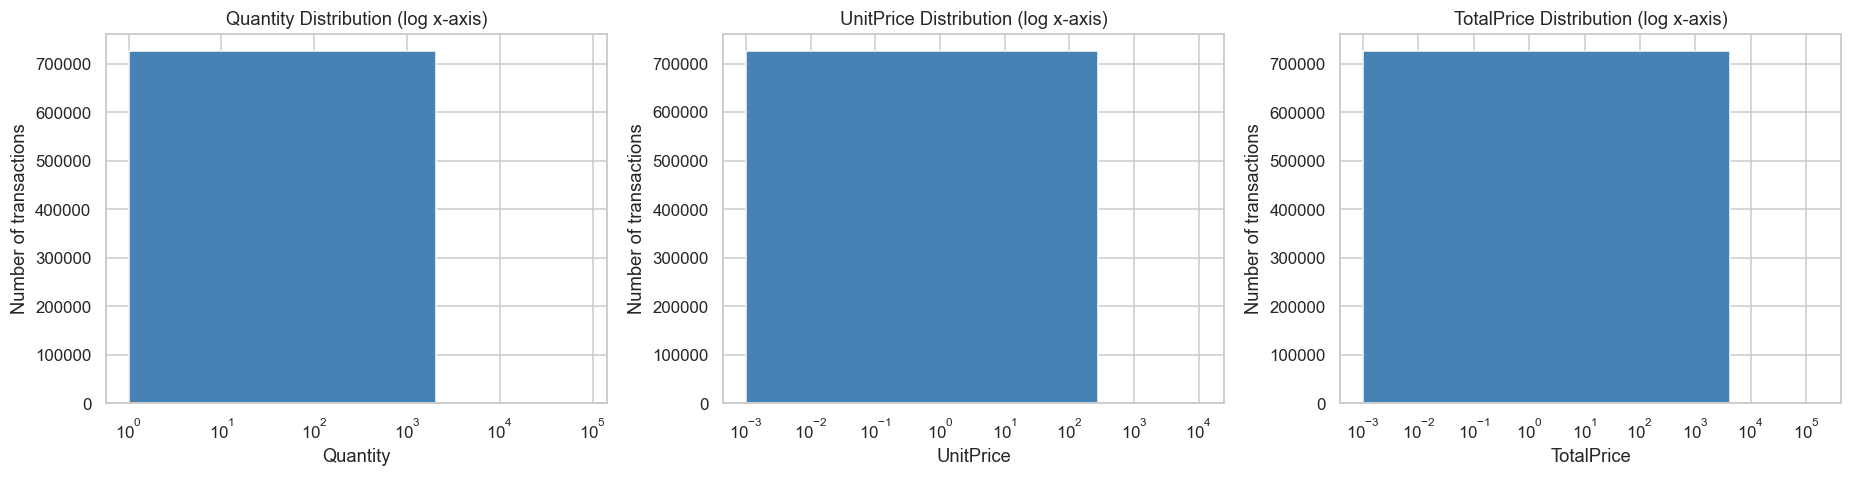

In [4]:
# Histograms for the three transaction-level numeric fields
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, column in zip(axes, ['Quantity', 'UnitPrice', 'TotalPrice']):
    positive_values = uk_df[column][uk_df[column] > 0]
    ax.hist(positive_values, bins=40, color='steelblue', edgecolor='white')
    ax.set_xscale('log')
    ax.set_title(f'{column} Distribution (log x-axis)')
    ax.set_xlabel(column)
    ax.set_ylabel('Number of transactions')
plt.tight_layout()
plt.show()

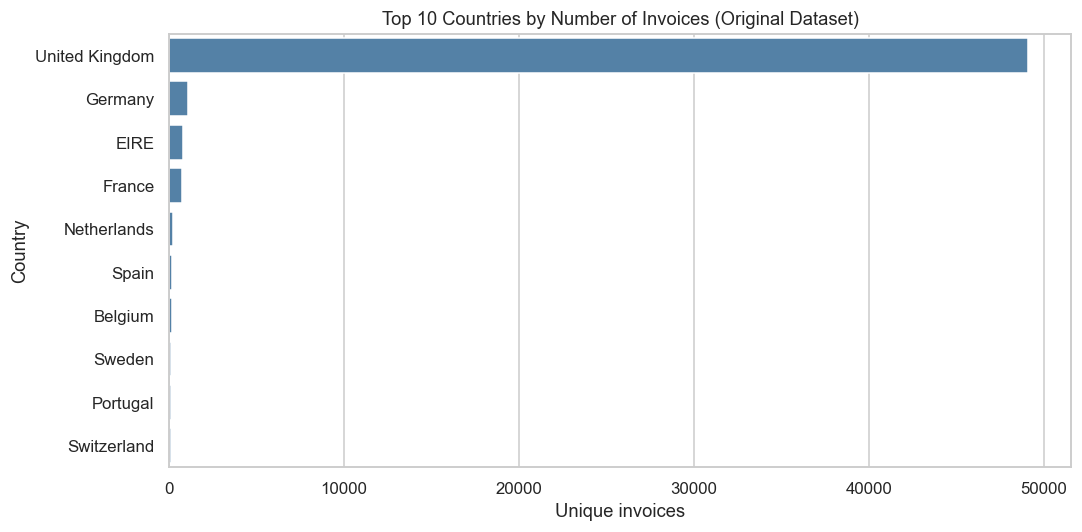

In [5]:
# Country context before restricting the dataset to the UK
country_orders = country_context.groupby('Country')['InvoiceNo'].nunique().sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=country_orders.values, y=country_orders.index, color='steelblue')
plt.title('Top 10 Countries by Number of Invoices (Original Dataset)')
plt.xlabel('Unique invoices')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

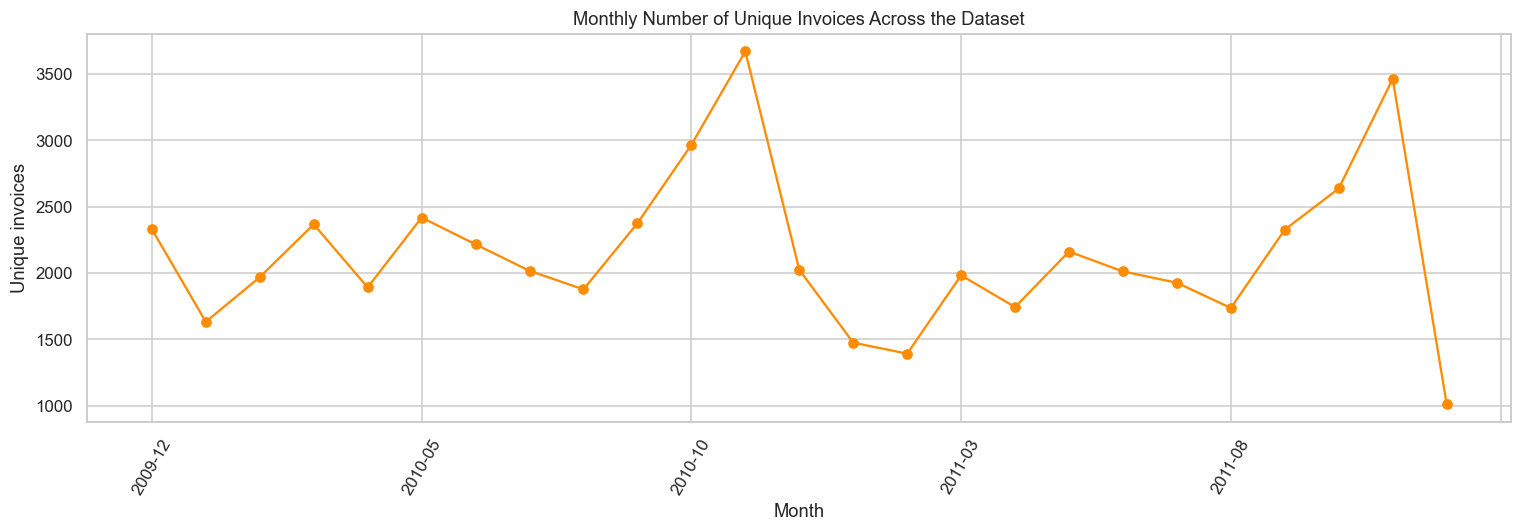

Monthly invoice count range: 2009-12 to 2011-12


In [6]:
# Monthly transaction counts across the available dataset period
monthly_transactions = (
    raw_df.assign(InvoiceDate=pd.to_datetime(raw_df['InvoiceDate'], errors='coerce'))
          .dropna(subset=['InvoiceDate'])
          .groupby(raw_df['InvoiceDate'].astype(str).str[:7])['InvoiceNo']
          .nunique()
)
plt.figure(figsize=(14, 5))
monthly_transactions.plot(marker='o', color='darkorange')
plt.title('Monthly Number of Unique Invoices Across the Dataset')
plt.xlabel('Month')
plt.ylabel('Unique invoices')
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()
print('Monthly invoice count range:', monthly_transactions.index.min(), 'to', monthly_transactions.index.max())

### 1.3 Customer-Level Analysis

Before creating RFM, I will summarize spending and order activity at customer level. This gives us an early view of the customers who contribute most to sales and whether the revenue distribution is concentrated among a smaller group.

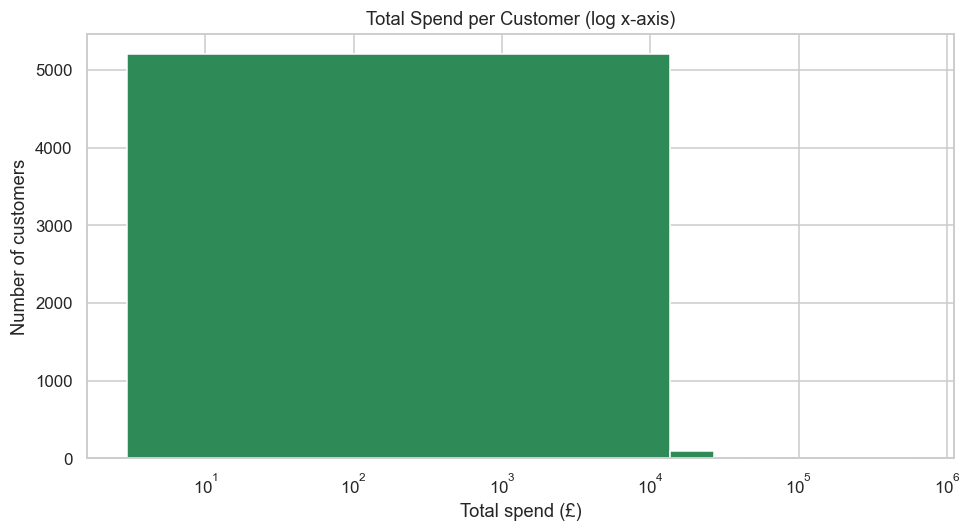

Top 10 customers by invoice frequency:


,OrderCount
CustomerID,
12748.0,336
17841.0,211
15311.0,208
13089.0,203
14606.0,192
17850.0,155
18102.0,145
13694.0,143
15061.0,127


Unique cleaned customers: 5350
1,301 customers (24.32%) account for approximately 80% of revenue.


In [7]:
customer_spend = uk_df.groupby('CustomerID')['TotalPrice'].sum().sort_values(ascending=False)
plt.figure(figsize=(9, 5))
plt.hist(customer_spend[customer_spend > 0], bins=45, color='seagreen', edgecolor='white')
plt.xscale('log')
plt.title('Total Spend per Customer (log x-axis)')
plt.xlabel('Total spend (£)')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.show()

customer_order_count = uk_df.groupby('CustomerID')['InvoiceNo'].nunique().sort_values(ascending=False)
print('Top 10 customers by invoice frequency:')
display(customer_order_count.head(10).rename('OrderCount').to_frame())
print('Unique cleaned customers:', uk_df['CustomerID'].nunique())

# Revenue concentration: how many customers are needed to reach 80% of revenue?
spend_sorted = customer_spend.sort_values(ascending=False)
cumulative_revenue_share = spend_sorted.cumsum() / spend_sorted.sum()
customers_for_80 = int((cumulative_revenue_share <= 0.80).sum()) + 1
percent_customers_for_80 = customers_for_80 / len(spend_sorted) * 100
print(f'{customers_for_80:,} customers ({percent_customers_for_80:.2f}%) account for approximately 80% of revenue.')

## 🔧 Step 2 — RFM Feature Engineering & Preprocessing

RFM is a simple way to summarize customer behaviour:
- **Recency:** how recently a customer purchased (smaller is better)
- **Frequency:** how many different invoices/orders they placed (larger is more active)
- **Monetary:** how much they spent in total (larger means higher spending)

These features help us compare customers using behaviour rather than personal assumptions.

### 2.1 Build the RFM Table

The reference date is fixed at **2011-12-31**, as required by the exam. Frequency is based on unique invoice numbers, while Monetary is the total transaction value for each customer.

In [8]:
reference_date = pd.Timestamp('2011-12-31')
rfm_df = uk_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda dates: (reference_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

print('RFM table shape:', rfm_df.shape)
display(rfm_df.head())
print('\nRFM descriptive statistics:')
display(rfm_df[['Recency', 'Frequency', 'Monetary']].describe())

RFM table shape: (5350, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346.0,346,12,77556.46
1,12608.0,425,1,415.79
2,12745.0,507,2,723.85
3,12746.0,561,1,254.55
4,12747.0,23,26,9276.54



RFM descriptive statistics:


,Recency,Frequency,Monetary
count,5350.000000,5350.000000,5350.000000
mean,223.546168,6.269346,2751.990190
std,209.973818,11.995550,12080.466564
min,21.000000,1.000000,2.950000
25%,46.000000,1.000000,336.167500
50%,119.000000,3.000000,849.910000
75%,402.000000,7.000000,2214.905000
max,759.000000,336.000000,608821.650000


### 2.2 Handle Outliers — IQR Winsorization

Extreme values are part of real retail behaviour, so I will not remove customers simply because they spend or order a lot. Instead, the exam asks us to cap upper outliers using **Q3 + 3 × IQR**. This limits the effect of unusually large values on distance-based clustering while keeping every customer in the dataset.

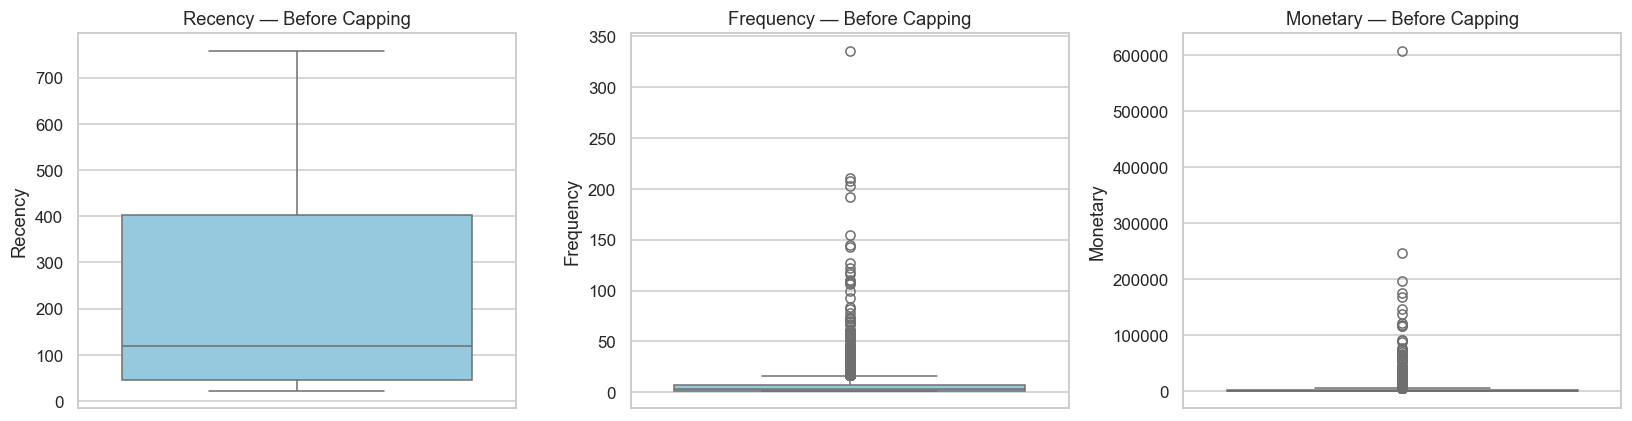

Upper cap thresholds:


Recency      1470.0000
Frequency      25.0000
Monetary     7851.1175
Name: UpperCap, dtype: float64

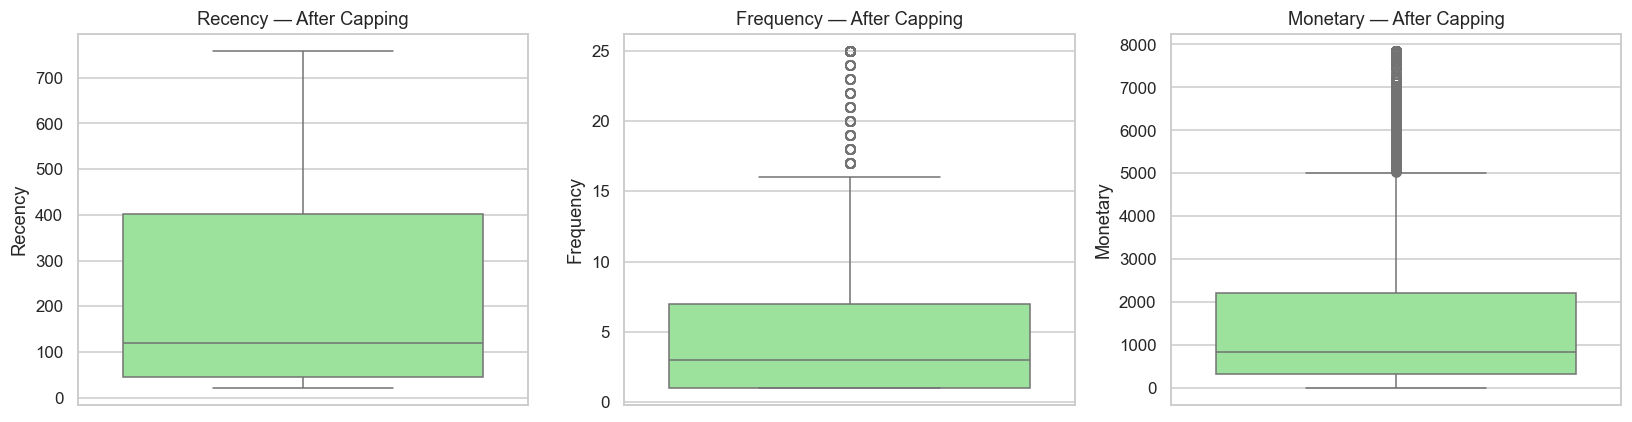

In [9]:
rfm_features = ['Recency', 'Frequency', 'Monetary']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, rfm_features):
    sns.boxplot(y=rfm_df[feature], ax=ax, color='skyblue')
    ax.set_title(f'{feature} — Before Capping')
plt.tight_layout()
plt.show()

rfm_capped = rfm_df.copy()
cap_limits = {}
for feature in rfm_features:
    q1 = rfm_capped[feature].quantile(0.25)
    q3 = rfm_capped[feature].quantile(0.75)
    iqr = q3 - q1
    upper_limit = q3 + 3 * iqr
    cap_limits[feature] = upper_limit
    rfm_capped[feature] = rfm_capped[feature].clip(upper=upper_limit)

print('Upper cap thresholds:')
display(pd.Series(cap_limits, name='UpperCap'))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, rfm_features):
    sns.boxplot(y=rfm_capped[feature], ax=ax, color='lightgreen')
    ax.set_title(f'{feature} — After Capping')
plt.tight_layout()
plt.show()

### 2.3 Transform Skewed Features

Frequency and Monetary often have a long right tail. The `log1p` transformation is `log(1 + x)`, which compresses very large values while still allowing zero values. Recency stays in its original form, as requested.

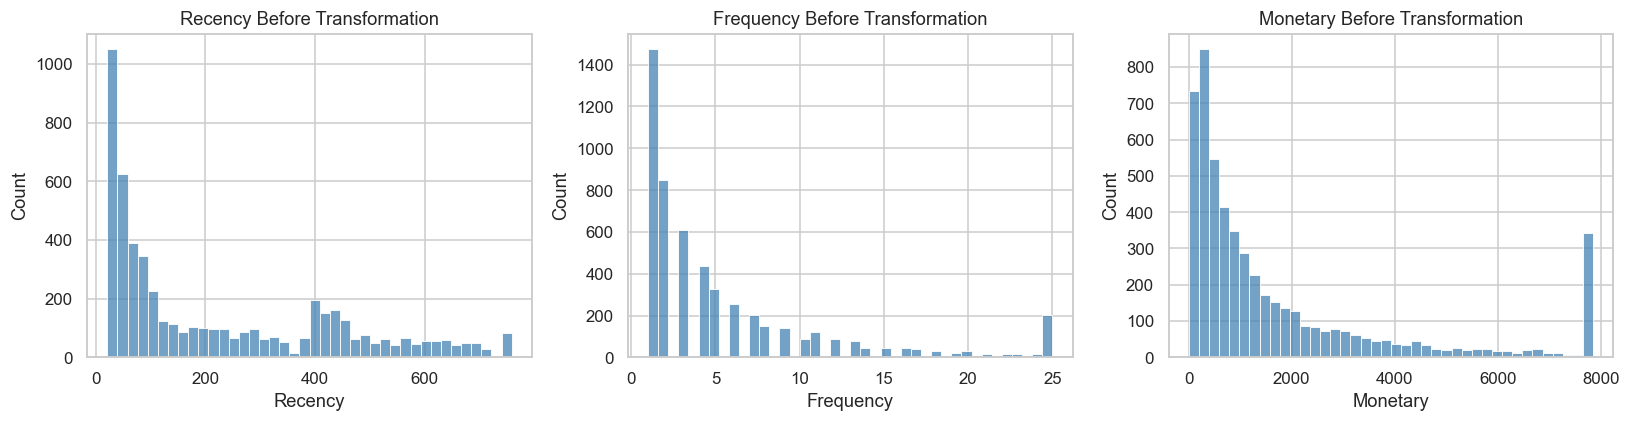

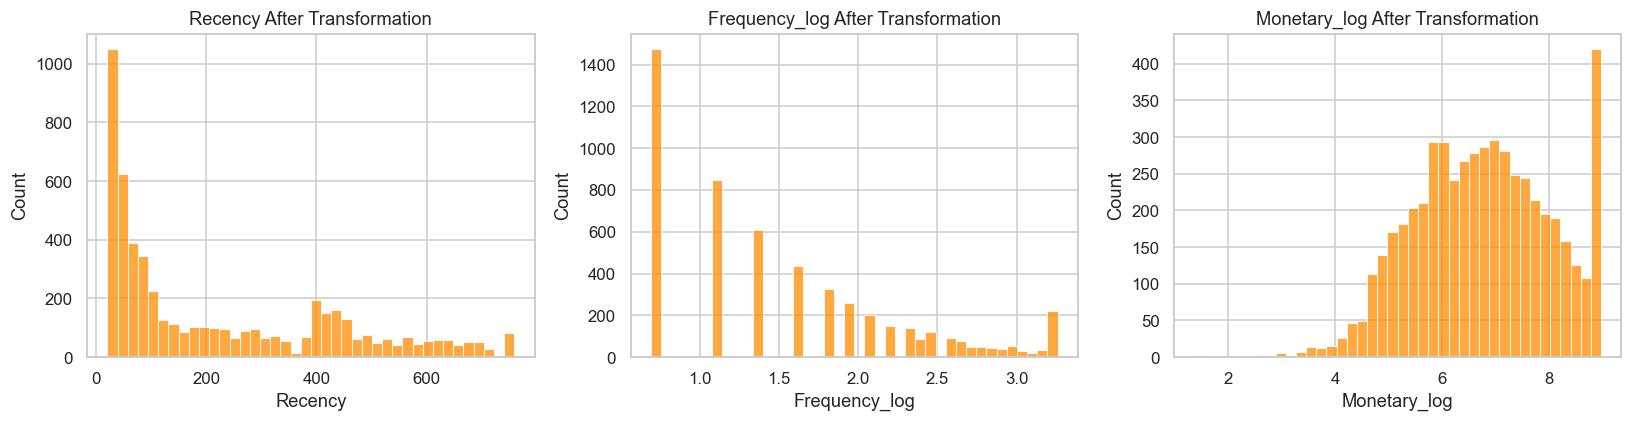

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, rfm_features):
    sns.histplot(rfm_capped[feature], bins=40, ax=ax, color='steelblue')
    ax.set_title(f'{feature} Before Transformation')
plt.tight_layout()
plt.show()

rfm_prepared = rfm_capped.copy()
rfm_prepared['Frequency_log'] = np.log1p(rfm_prepared['Frequency'])
rfm_prepared['Monetary_log'] = np.log1p(rfm_prepared['Monetary'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ['Recency', 'Frequency_log', 'Monetary_log']):
    sns.histplot(rfm_prepared[feature], bins=40, ax=ax, color='darkorange')
    ax.set_title(f'{feature} After Transformation')
plt.tight_layout()
plt.show()

### 2.4 Scale the Features

The RFM features use different units and ranges. If I cluster without scaling, Monetary could dominate simply because its numbers are much larger. `StandardScaler` places the features on a comparable scale, which is important for all three algorithms in this exam.

In [11]:
scaling_features = ['Recency', 'Frequency_log', 'Monetary_log']
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_prepared[scaling_features])

scaled_check = pd.DataFrame(rfm_scaled, columns=scaling_features)
print('Scaled feature means (should be close to 0):')
display(scaled_check.mean().to_frame('Mean'))
print('Scaled feature standard deviations (should be close to 1):')
display(scaled_check.std(ddof=0).to_frame('StandardDeviation'))

Scaled feature means (should be close to 0):


,Mean
Recency,-2.224596e-17
Frequency_log,3.927907e-16
Monetary_log,3.214044e-16


Scaled feature standard deviations (should be close to 1):


,StandardDeviation
Recency,1.0
Frequency_log,1.0
Monetary_log,1.0


## 🔵 Step 3 — K-Means Clustering

K-Means groups customers into a chosen number of clusters. It repeatedly assigns each customer to the closest centroid and updates the centroid until the groups stop changing much. I will use the Elbow Method and Silhouette Score together rather than choosing K based on only one number.

### 3.1 Elbow Method and Silhouette Score

I will test K values from 2 to 10. Inertia (within-cluster sum of squares) decreases as K increases, so the elbow plot helps identify where additional clusters provide diminishing improvement. The silhouette score gives another view of how separated and compact the groups are.

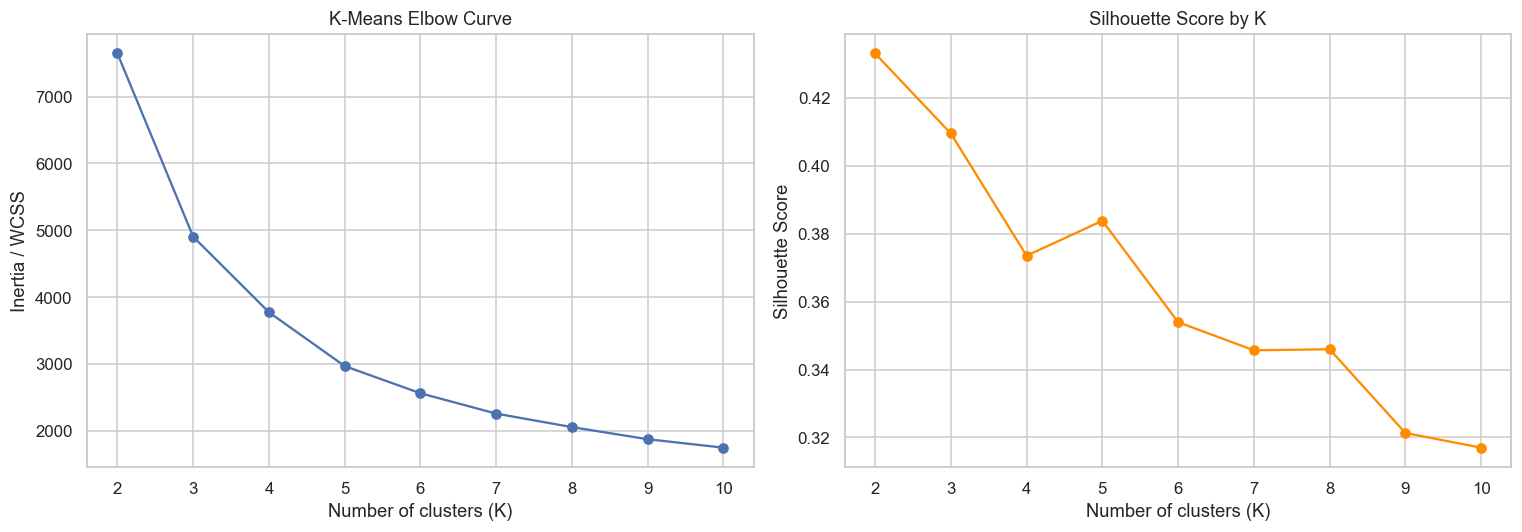

,K,Inertia,Silhouette
0,2,7644.706253,0.433091
1,3,4903.889426,0.409523
2,4,3773.791621,0.373525
3,5,2969.205917,0.383819
4,6,2562.196718,0.353965
5,7,2258.052194,0.345668
6,8,2056.307509,0.345983
7,9,1874.773638,0.321326
8,10,1748.593656,0.316991


Highest silhouette score occurs at K = 2
Use the elbow curve together with the silhouette plot and business interpretability to choose K.


In [12]:
k_values = range(2, 11)
inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = model.fit_predict(rfm_scaled)
    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_values), inertia_values, marker='o')
axes[0].set_title('K-Means Elbow Curve')
axes[0].set_xlabel('Number of clusters (K)')
axes[0].set_ylabel('Inertia / WCSS')
axes[0].set_xticks(list(k_values))
axes[1].plot(list(k_values), silhouette_values, marker='o', color='darkorange')
axes[1].set_title('Silhouette Score by K')
axes[1].set_xlabel('Number of clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticks(list(k_values))
plt.tight_layout()
plt.show()

k_results = pd.DataFrame({'K': list(k_values), 'Inertia': inertia_values, 'Silhouette': silhouette_values})
display(k_results)
best_silhouette_k = int(k_results.loc[k_results['Silhouette'].idxmax(), 'K'])
print('Highest silhouette score occurs at K =', best_silhouette_k)
print('Use the elbow curve together with the silhouette plot and business interpretability to choose K.')

### Selecting K — my decision

The following cell provides a decision scaffold based on the real scores. I will choose the value that balances a visible bend in the inertia curve, a reasonable silhouette score, and clusters that can be described meaningfully for marketing. The silhouette maximum is useful evidence, but it is not automatically the best business segmentation.

In [13]:
# The silhouette score is strongest at K=2 in this run, and the elbow plot
# also shows a large early reduction in inertia. I choose two broad segments.
k_optimal = best_silhouette_k
print('Chosen K for final K-Means:', k_optimal)
print(f'Silhouette at K={k_optimal}: {k_results.loc[k_results["K"] == k_optimal, "Silhouette"].iloc[0]:.4f}')
print('I selected K=2 because it is the best-scoring candidate in the tested range and gives an easy-to-interpret starting segmentation.')

Chosen K for final K-Means: 2
Silhouette at K=2: 0.4331
I selected K=2 because it is the best-scoring candidate in the tested range and gives an easy-to-interpret starting segmentation.


### 3.2 Train the Final K-Means Model

I will train the final model using the exam settings and attach the cluster labels to the customer-level RFM table. The labels are just identifiers; the real meaning comes from each cluster’s RFM averages.

In [14]:
kmeans_model = KMeans(
    n_clusters=k_optimal,
    init='k-means++',
    n_init=20,
    max_iter=500,
    random_state=42
)
kmeans_labels = kmeans_model.fit_predict(rfm_scaled)
rfm_results = rfm_prepared.copy()
rfm_results['KMeans_Cluster'] = kmeans_labels
print('K-Means cluster sizes:')
display(rfm_results['KMeans_Cluster'].value_counts().sort_index().to_frame('Customers'))

K-Means cluster sizes:


,Customers
KMeans_Cluster,
0,2827
1,2523


### 3.3 Visualise K-Means Clusters

The two-dimensional plots show different pairs of RFM features. The 3D plot brings all three original RFM dimensions together. I use the original (capped) RFM values for the axes so the results are easier to explain to a marketing audience.

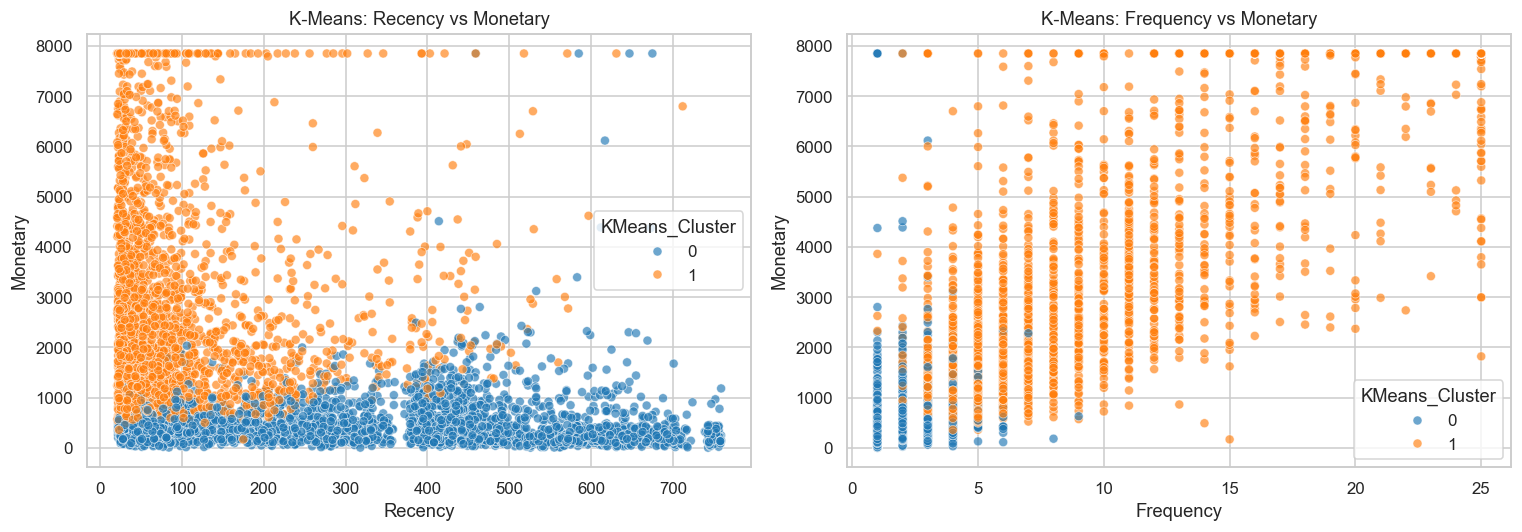

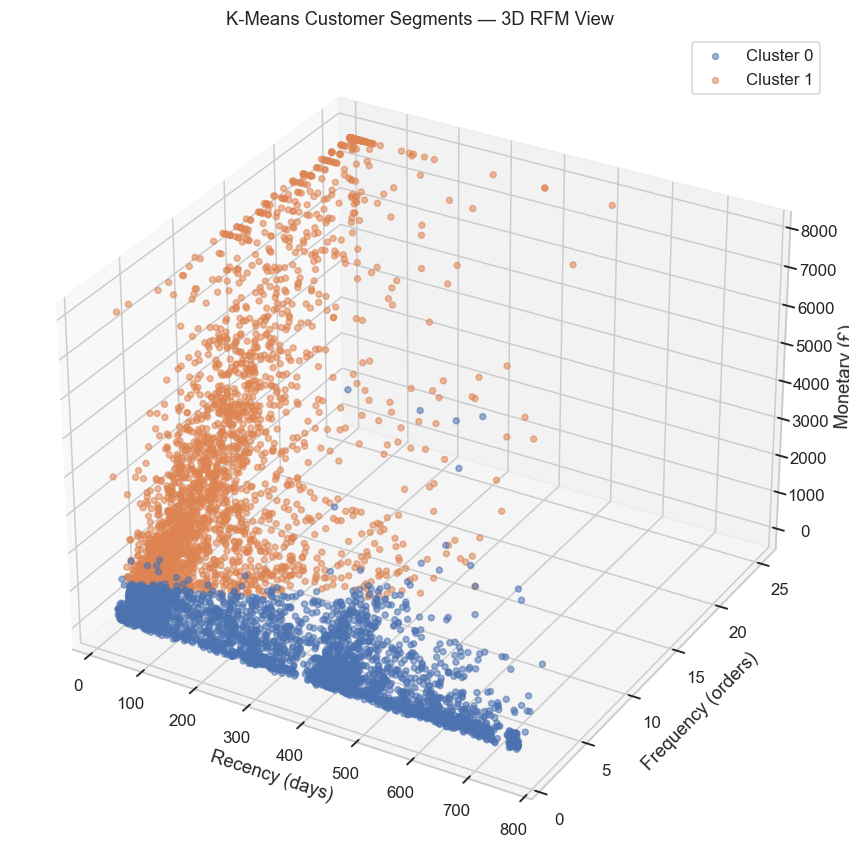

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=rfm_results, x='Recency', y='Monetary', hue='KMeans_Cluster', palette='tab10', alpha=0.65, s=35, ax=axes[0])
axes[0].set_title('K-Means: Recency vs Monetary')
sns.scatterplot(data=rfm_results, x='Frequency', y='Monetary', hue='KMeans_Cluster', palette='tab10', alpha=0.65, s=35, ax=axes[1])
axes[1].set_title('K-Means: Frequency vs Monetary')
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for cluster in sorted(rfm_results['KMeans_Cluster'].unique()):
    part = rfm_results[rfm_results['KMeans_Cluster'] == cluster]
    ax.scatter(part['Recency'], part['Frequency'], part['Monetary'], s=15, alpha=0.55, label=f'Cluster {cluster}')
ax.set_title('K-Means Customer Segments — 3D RFM View')
ax.set_xlabel('Recency (days)')
ax.set_ylabel('Frequency (orders)')
ax.set_zlabel('Monetary (£)')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

### 3.4 Profile K-Means Clusters

I will compare the cluster averages on the original RFM scale. For this business problem, a customer who purchased recently, placed many orders and spent a lot is generally more valuable than a customer with high recency and very low activity. I will assign personas only after looking at the actual averages.

In [16]:
kmeans_profile = rfm_results.groupby('KMeans_Cluster')[rfm_features].mean().sort_values('Monetary', ascending=False)
kmeans_sizes = rfm_results.groupby('KMeans_Cluster').size().rename('CustomerCount')
kmeans_profile = kmeans_profile.join(kmeans_sizes)
display(kmeans_profile.round(2))

# Persona labels are generated from the observed cluster profile, using simple RFM logic.
def rfm_persona(row, recency_median, frequency_median, monetary_median):
    if row['Recency'] <= recency_median and row['Frequency'] >= frequency_median and row['Monetary'] >= monetary_median:
        return 'Champions / VIPs'
    if row['Recency'] <= recency_median and row['Frequency'] >= frequency_median:
        return 'Loyal Customers'
    if row['Recency'] > recency_median and row['Frequency'] >= frequency_median:
        return 'At-Risk Loyal Customers'
    if row['Recency'] <= recency_median and row['Frequency'] < frequency_median:
        return 'Recent / New Customers'
    return 'Hibernating / Low Activity'

rfm_medians = rfm_prepared[rfm_features].median()
kmeans_profile['Persona'] = kmeans_profile.apply(
    lambda row: rfm_persona(row, rfm_medians['Recency'], rfm_medians['Frequency'], rfm_medians['Monetary']), axis=1
)
display(kmeans_profile.round(2))
print('Persona names are starting labels; validate them against the cluster averages before using them in campaigns.')

,Recency,Frequency,Monetary,CustomerCount
KMeans_Cluster,,,,
1,90.49,9.47,3219.12,2523
0,342.30,1.80,478.47,2827


,Recency,Frequency,Monetary,CustomerCount,Persona
KMeans_Cluster,,,,,
1,90.49,9.47,3219.12,2523,Champions / VIPs
0,342.30,1.80,478.47,2827,Hibernating / Low Activity


Persona names are starting labels; validate them against the cluster averages before using them in campaigns.


## 🌳 Step 4 — Agglomerative Hierarchical Clustering

Agglomerative clustering starts with each customer as their own group and repeatedly merges the closest groups. The dendrogram helps us visualize how those merges happen and where a reasonable cut could be made. I will follow the course notebook approach with SciPy `linkage` and sklearn `AgglomerativeClustering`.

### 4.1 Dendrogram Analysis

The full customer dataset can produce a dense dendrogram, so I will use the exam’s truncated view (`truncate_mode="level", p=5`). The cut line is a visual aid; I will also compare the candidate cluster counts of 3, 4 and 5 using the scaled features.

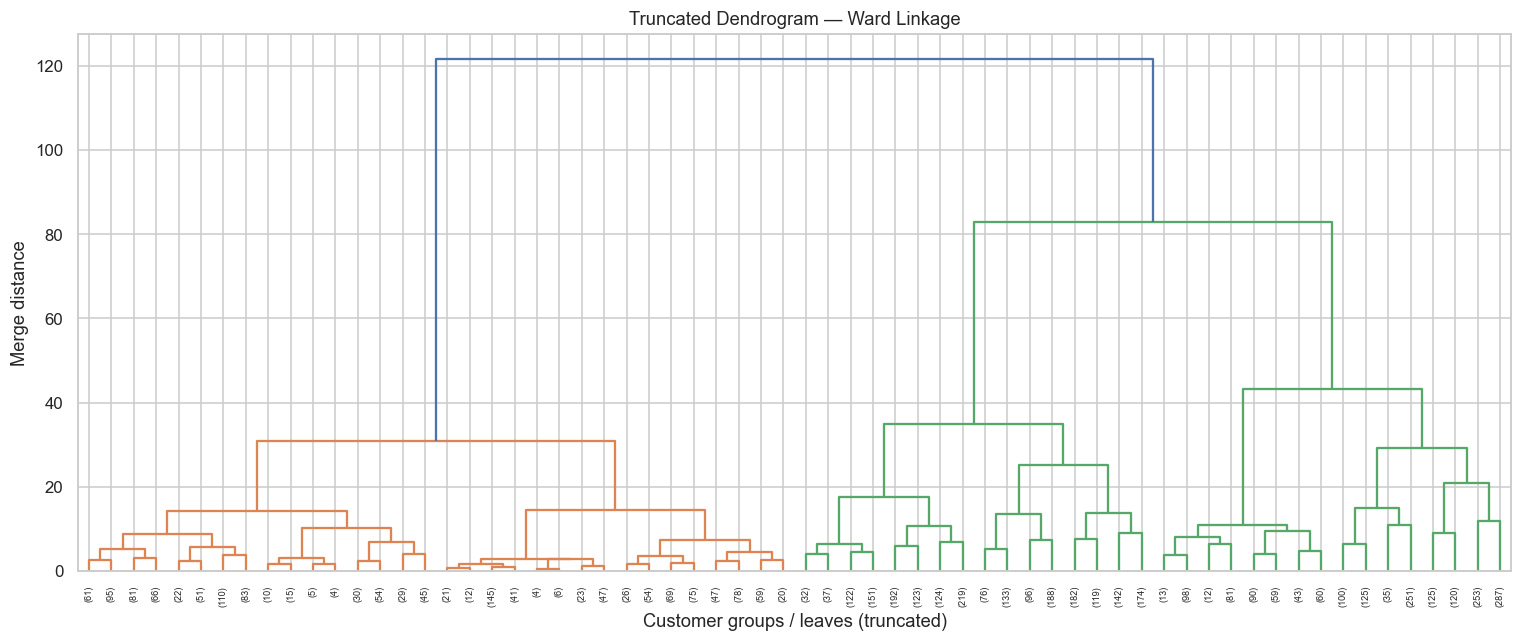

Approximate linkage heights associated with candidate cluster counts:


,ApproximateCutDistance
3,63.028469
4,39.044079
5,32.876607


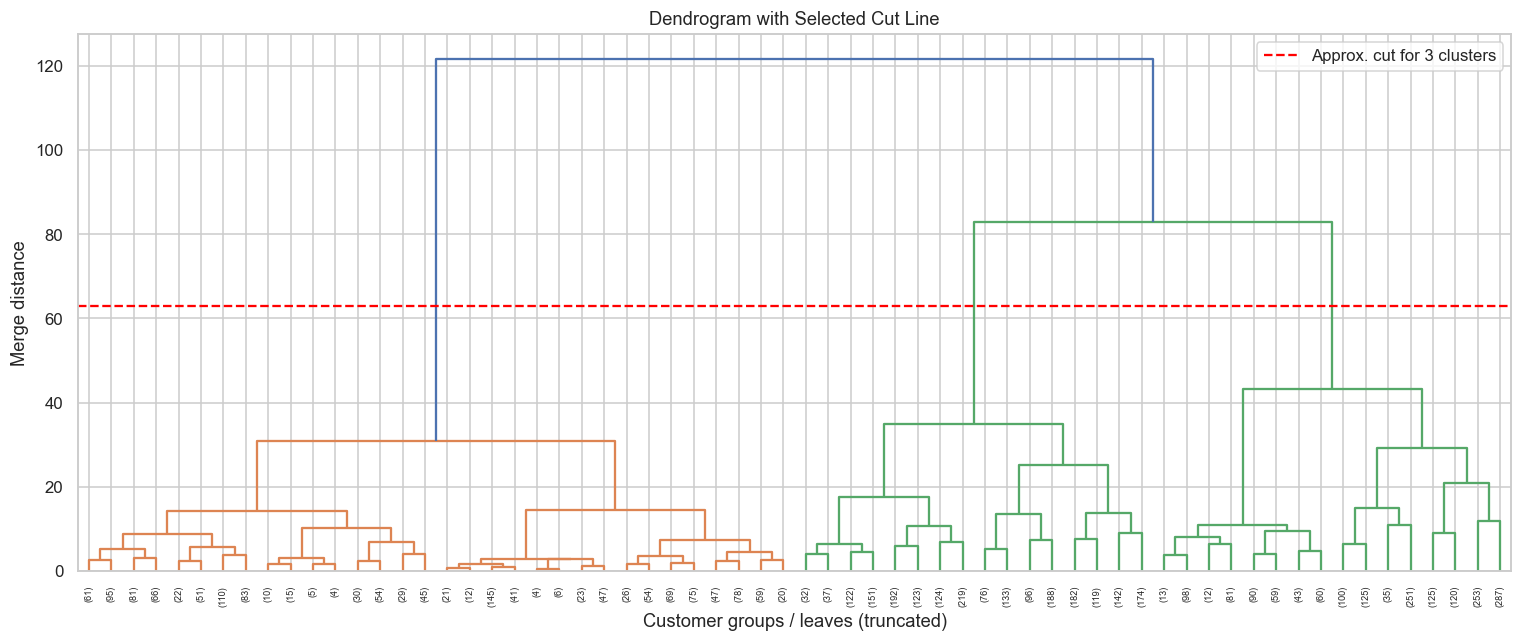

Chosen candidate: 3 clusters; cut distance = 63.028
Cluster count produced by this cut: 3


In [17]:
hierarchical_linkage = linkage(rfm_scaled, method='ward')
plt.figure(figsize=(14, 6))
dendrogram(hierarchical_linkage, truncate_mode='level', p=5, color_threshold=None)
plt.title('Truncated Dendrogram — Ward Linkage')
plt.xlabel('Customer groups / leaves (truncated)')
plt.ylabel('Merge distance')
plt.tight_layout()
plt.show()

# Candidate cut distances are estimated from the linkage heights for k=3,4,5.
linkage_heights = hierarchical_linkage[:, 2]
cut_candidates = {}
for candidate_k in [3, 4, 5]:
    # Place the cut between the merge creating k clusters and the next merge.
    previous_merge = linkage_heights[-candidate_k]
    next_merge = linkage_heights[-(candidate_k - 1)]
    cut_distance = (previous_merge + next_merge) / 2
    cut_candidates[candidate_k] = cut_distance
print('Approximate linkage heights associated with candidate cluster counts:')
display(pd.Series(cut_candidates, name='ApproximateCutDistance').to_frame())
chosen_hierarchical_k = 3
chosen_cut_distance = cut_candidates[chosen_hierarchical_k]
plt.figure(figsize=(14, 6))
dendrogram(hierarchical_linkage, truncate_mode='level', p=5)
plt.axhline(chosen_cut_distance, color='red', linestyle='--', label=f'Approx. cut for {chosen_hierarchical_k} clusters')
plt.title('Dendrogram with Selected Cut Line')
plt.xlabel('Customer groups / leaves (truncated)')
plt.ylabel('Merge distance')
plt.legend()
plt.tight_layout()
plt.show()
exact_cut_labels = fcluster(hierarchical_linkage, t=chosen_cut_distance, criterion='distance')
exact_cut_cluster_count = len(np.unique(exact_cut_labels))
print(f'Chosen candidate: {chosen_hierarchical_k} clusters; cut distance = {chosen_cut_distance:.3f}')
print('Cluster count produced by this cut:', exact_cut_cluster_count)

### 4.2 Train and Compare Linkage Methods

Ward, Complete and Average linkage can produce different group shapes. I will compare their silhouette scores using the same number of clusters and scaled RFM features. Ward is the course-style starting point, but the score comparison gives us evidence for the final choice.

In [18]:
linkage_methods = ['ward', 'complete', 'average']
linkage_models = {}
linkage_scores = {}
for method in linkage_methods:
    model = AgglomerativeClustering(n_clusters=chosen_hierarchical_k, linkage=method)
    labels = model.fit_predict(rfm_scaled)
    linkage_models[method] = model
    linkage_scores[method] = silhouette_score(rfm_scaled, labels)

linkage_comparison = pd.DataFrame({'Linkage': list(linkage_scores.keys()), 'SilhouetteScore': list(linkage_scores.values())}).sort_values('SilhouetteScore', ascending=False)
display(linkage_comparison)
best_linkage = linkage_comparison.iloc[0]['Linkage']
agg_model = linkage_models[best_linkage]
agg_labels = agg_model.labels_
rfm_results['Agg_Cluster'] = agg_labels
print('Selected linkage:', best_linkage)

,Linkage,SilhouetteScore
0,ward,0.385891
1,complete,0.326480
2,average,0.321314


Selected linkage: ward


### 4.3 Visualise & Profile Hierarchical Clusters

I will plot the selected hierarchical solution in 2D and 3D, then compare its cluster profiles with K-Means. The cluster numbers from the two algorithms are not directly comparable because label 0 in one model does not necessarily mean label 0 in another model.

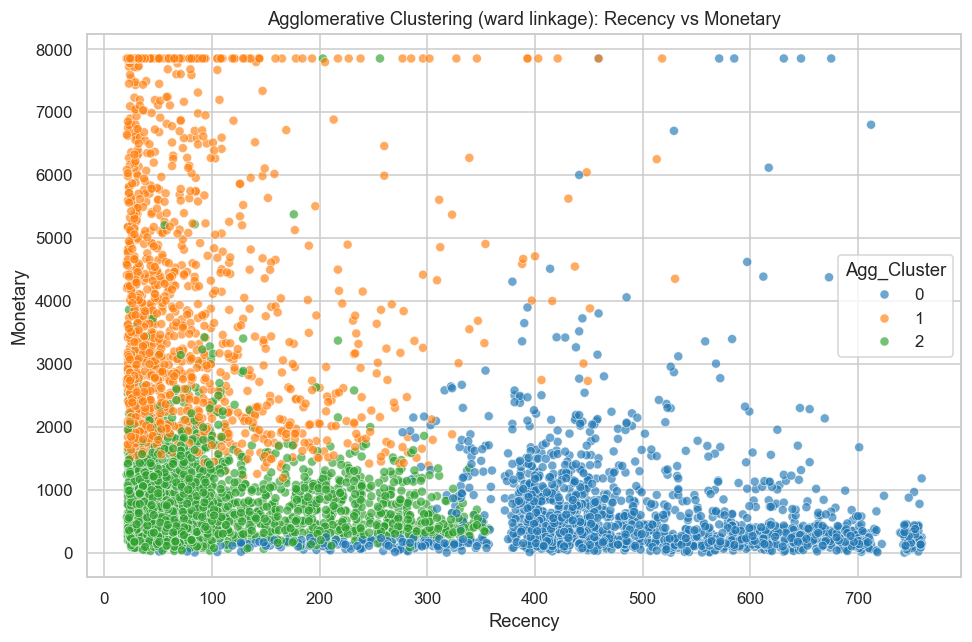

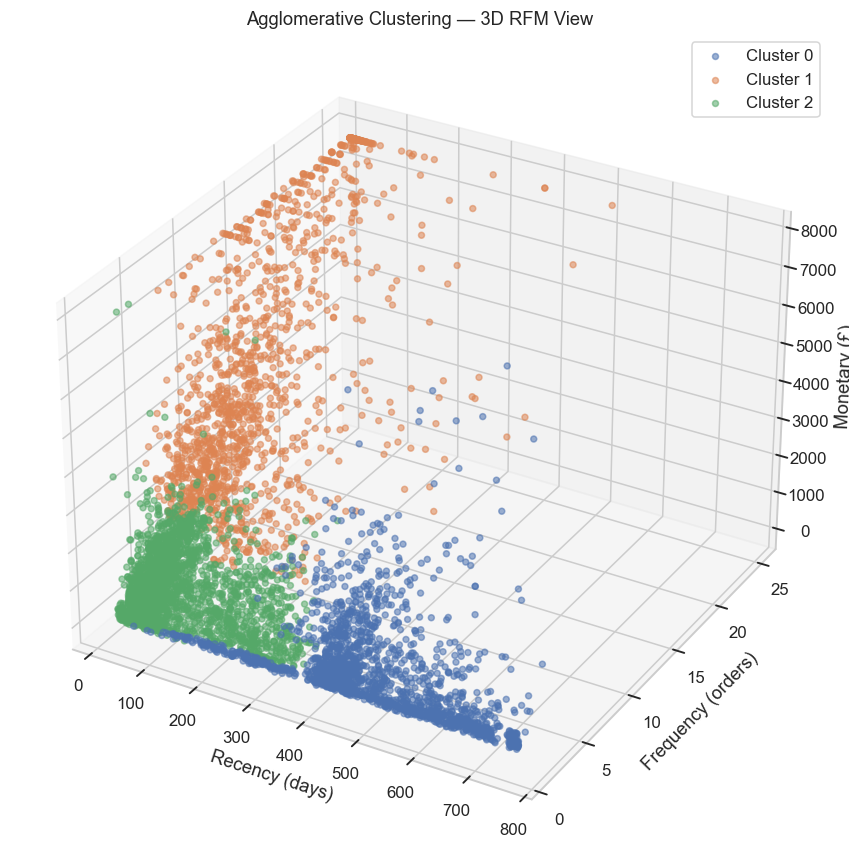

,Recency,Frequency,Monetary,CustomerCount,Persona
Agg_Cluster,,,,,
1,77.81,12.91,4498.76,1488,Champions / VIPs
2,109.34,2.99,824.22,2110,Recent / New Customers
0,484.86,1.97,594.30,1752,Hibernating / Low Activity


In [19]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=rfm_results, x='Recency', y='Monetary', hue='Agg_Cluster', palette='tab10', alpha=0.65, s=35, ax=ax)
ax.set_title(f'Agglomerative Clustering ({best_linkage} linkage): Recency vs Monetary')
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for cluster in sorted(rfm_results['Agg_Cluster'].unique()):
    part = rfm_results[rfm_results['Agg_Cluster'] == cluster]
    ax.scatter(part['Recency'], part['Frequency'], part['Monetary'], s=15, alpha=0.55, label=f'Cluster {cluster}')
ax.set_title('Agglomerative Clustering — 3D RFM View')
ax.set_xlabel('Recency (days)')
ax.set_ylabel('Frequency (orders)')
ax.set_zlabel('Monetary (£)')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

agg_profile = rfm_results.groupby('Agg_Cluster')[rfm_features].mean().sort_values('Monetary', ascending=False)
agg_profile['CustomerCount'] = rfm_results.groupby('Agg_Cluster').size()
agg_profile['Persona'] = agg_profile.apply(lambda row: rfm_persona(row, rfm_medians['Recency'], rfm_medians['Frequency'], rfm_medians['Monetary']), axis=1)
display(agg_profile.round(2))

### K-Means vs Hierarchical — quick comparison

To compare the two segmentations, I will check how often the customer pairs agree using Adjusted Rand Index (ARI). ARI is not a business metric; it simply summarizes similarity between two sets of cluster assignments while accounting for chance. A lower agreement can still be useful because the algorithms may reveal different views of customer behaviour.

In [20]:
kmeans_vs_agg_ari = adjusted_rand_score(rfm_results['KMeans_Cluster'], rfm_results['Agg_Cluster'])
print(f'Adjusted Rand Index between K-Means and Agglomerative: {kmeans_vs_agg_ari:.3f}')
print('K-Means profiles:')
display(kmeans_profile.round(2))
print('Hierarchical profiles:')
display(agg_profile.round(2))

Adjusted Rand Index between K-Means and Agglomerative: 0.325
K-Means profiles:


,Recency,Frequency,Monetary,CustomerCount,Persona
KMeans_Cluster,,,,,
1,90.49,9.47,3219.12,2523,Champions / VIPs
0,342.30,1.80,478.47,2827,Hibernating / Low Activity


Hierarchical profiles:


,Recency,Frequency,Monetary,CustomerCount,Persona
Agg_Cluster,,,,,
1,77.81,12.91,4498.76,1488,Champions / VIPs
2,109.34,2.99,824.22,2110,Recent / New Customers
0,484.86,1.97,594.30,1752,Hibernating / Low Activity


## 🔴 Step 5 — DBSCAN Clustering

DBSCAN groups points that are close together in dense regions. Unlike K-Means and Agglomerative clustering, I do not need to specify the number of clusters in advance. It can also label customers as noise (`-1`) when they do not fit into a dense group. The algorithm is sensitive to epsilon and minimum samples, so I will tune these parameters.

### 5.1 Choose Epsilon Using a k-NN Distance Plot

I will calculate each customer’s distance to their fifth nearest neighbour and sort those distances. The bend in the curve is a useful starting point for epsilon, but the final choice should also be checked through the resulting cluster sizes and scores.

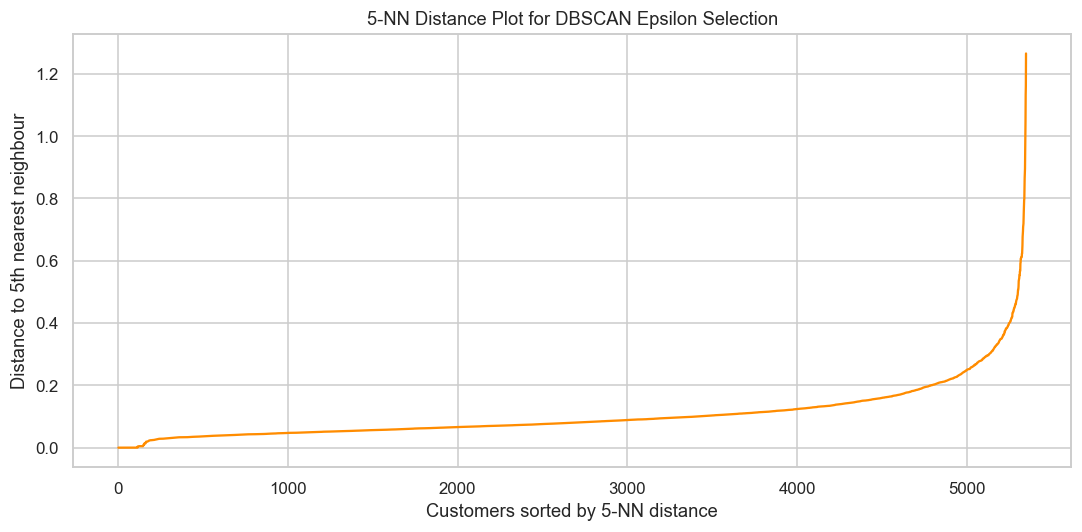

Initial epsilon estimate (90th percentile of 5-NN distances): 0.204
This is a reproducible starting estimate; the parameter grid below checks which setting produces a useful segmentation.


In [21]:
min_samples_start = 5
nearest_neighbors = NearestNeighbors(n_neighbors=min_samples_start)
nearest_neighbors.fit(rfm_scaled)
distances, neighbor_indices = nearest_neighbors.kneighbors(rfm_scaled)
k_distance = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(k_distance, color='darkorange')
plt.title('5-NN Distance Plot for DBSCAN Epsilon Selection')
plt.xlabel('Customers sorted by 5-NN distance')
plt.ylabel('Distance to 5th nearest neighbour')
plt.tight_layout()
plt.show()

# Initial epsilon estimate from a high percentile near the curve's bend; review against the plot.
optimal_eps_initial = float(np.percentile(k_distance, 90))
print(f'Initial epsilon estimate (90th percentile of 5-NN distances): {optimal_eps_initial:.3f}')
print('This is a reproducible starting estimate; the parameter grid below checks which setting produces a useful segmentation.')

### 5.2 Train an Initial DBSCAN Model

I will start with the exam’s `min_samples=5` and the epsilon estimate from the distance plot. The model may produce many noise points or very few clusters; that is part of the diagnostic process, not necessarily a coding error.

In [22]:
dbscan_initial = DBSCAN(eps=optimal_eps_initial, min_samples=5, metric='euclidean')
dbscan_initial_labels = dbscan_initial.fit_predict(rfm_scaled)
rfm_results['DBSCAN_Initial'] = dbscan_initial_labels
initial_cluster_count = len(set(dbscan_initial_labels)) - (1 if -1 in dbscan_initial_labels else 0)
initial_noise_count = int(np.sum(dbscan_initial_labels == -1))
initial_noise_pct = initial_noise_count / len(dbscan_initial_labels) * 100
print('Initial DBSCAN clusters (excluding noise):', initial_cluster_count)
print('Noise customers:', initial_noise_count)
print(f'Noise percentage: {initial_noise_pct:.2f}%')
display(pd.Series(dbscan_initial_labels).value_counts().sort_index().to_frame('Customers'))

Initial DBSCAN clusters (excluding noise): 11
Noise customers: 342
Noise percentage: 6.39%


,Customers
-1,342
0,1382
1,800
2,1834
3,556
4,403
5,5
6,9
7,7
8,5


### 5.3 Tune DBSCAN Hyperparameters

The exam provides a grid of epsilon and `min_samples` values. I will test each combination and calculate silhouette only for non-noise points, provided there are at least two clusters and enough customers. For runtime, the silhouette calculation uses a reproducible sample when the non-noise population is large; the DBSCAN model itself is fit on all customers.

,eps,min_samples,Clusters,NoiseCount,NoisePercent,Silhouette
5,0.5,5,2,26,0.485981,0.333463
6,0.5,8,2,39,0.728972,0.333440
7,0.5,10,2,41,0.766355,0.333265
4,0.5,3,3,17,0.317757,0.304084
3,0.3,10,3,236,4.411215,0.201054
2,0.3,8,3,194,3.626168,0.198689
1,0.3,5,5,130,2.429907,0.105491
0,0.3,3,7,86,1.607477,0.005152
8,0.7,3,1,4,0.074766,NaN
9,0.7,5,1,6,0.112150,NaN


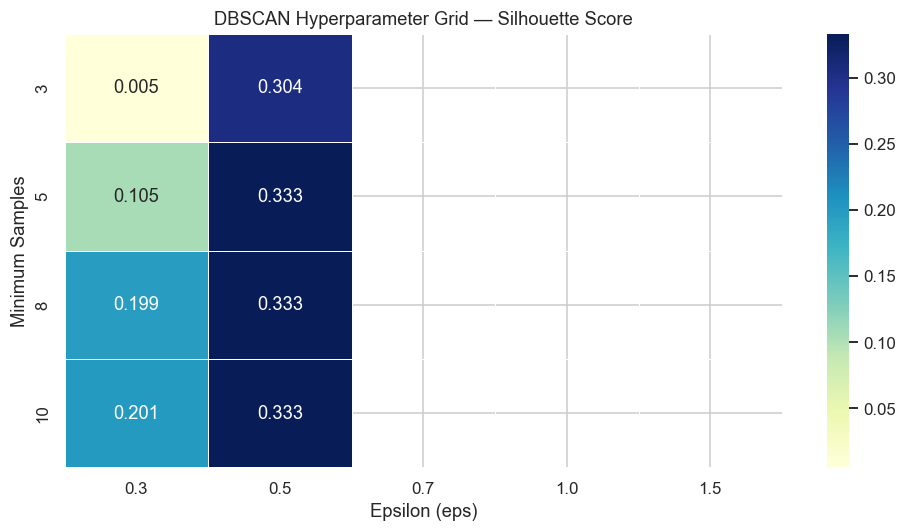

Best valid grid combination: eps=0.5, min_samples=5


In [23]:
eps_values = [0.3, 0.5, 0.7, 1.0, 1.5]
min_samples_values = [3, 5, 8, 10]
dbscan_grid_rows = []

for eps in eps_values:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps, min_samples=min_samples, metric='euclidean')
        labels = model.fit_predict(rfm_scaled)
        non_noise_mask = labels != -1
        non_noise_labels = labels[non_noise_mask]
        cluster_count = len(set(non_noise_labels))
        score = np.nan
        if cluster_count >= 2 and non_noise_mask.sum() > cluster_count:
            sample_size = min(10000, int(non_noise_mask.sum()))
            if non_noise_mask.sum() > sample_size:
                score = silhouette_score(rfm_scaled[non_noise_mask], non_noise_labels, sample_size=sample_size, random_state=42)
            else:
                score = silhouette_score(rfm_scaled[non_noise_mask], non_noise_labels)
        dbscan_grid_rows.append({
            'eps': eps, 'min_samples': min_samples, 'Clusters': cluster_count,
            'NoiseCount': int((labels == -1).sum()), 'NoisePercent': (labels == -1).mean() * 100,
            'Silhouette': score
        })

dbscan_grid = pd.DataFrame(dbscan_grid_rows)
display(dbscan_grid.sort_values('Silhouette', ascending=False))

heatmap_data = dbscan_grid.pivot(index='min_samples', columns='eps', values='Silhouette')
plt.figure(figsize=(9, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlGnBu', linewidths=0.5)
plt.title('DBSCAN Hyperparameter Grid — Silhouette Score')
plt.xlabel('Epsilon (eps)')
plt.ylabel('Minimum Samples')
plt.tight_layout()
plt.show()

valid_grid = dbscan_grid.dropna(subset=['Silhouette'])
if len(valid_grid):
    best_grid_row = valid_grid.sort_values('Silhouette', ascending=False).iloc[0]
    best_eps = float(best_grid_row['eps'])
    best_min_samples = int(best_grid_row['min_samples'])
    print(f'Best valid grid combination: eps={best_eps}, min_samples={best_min_samples}')
else:
    # If no setting creates at least two non-noise clusters, use a practical fallback
    best_eps, best_min_samples = 0.7, 5
    print('No valid silhouette combination found; fallback parameters selected for further inspection.')

### 5.4 Final DBSCAN, Visualisation & Profile

I will refit DBSCAN using the best valid grid setting. Noise points will be shown in grey so that they are easy to distinguish from the discovered clusters. I will profile the non-noise clusters separately because noise is not a customer persona.

Final DBSCAN clusters (excluding noise): 2
Noise customers: 26
Noise percentage: 0.49%


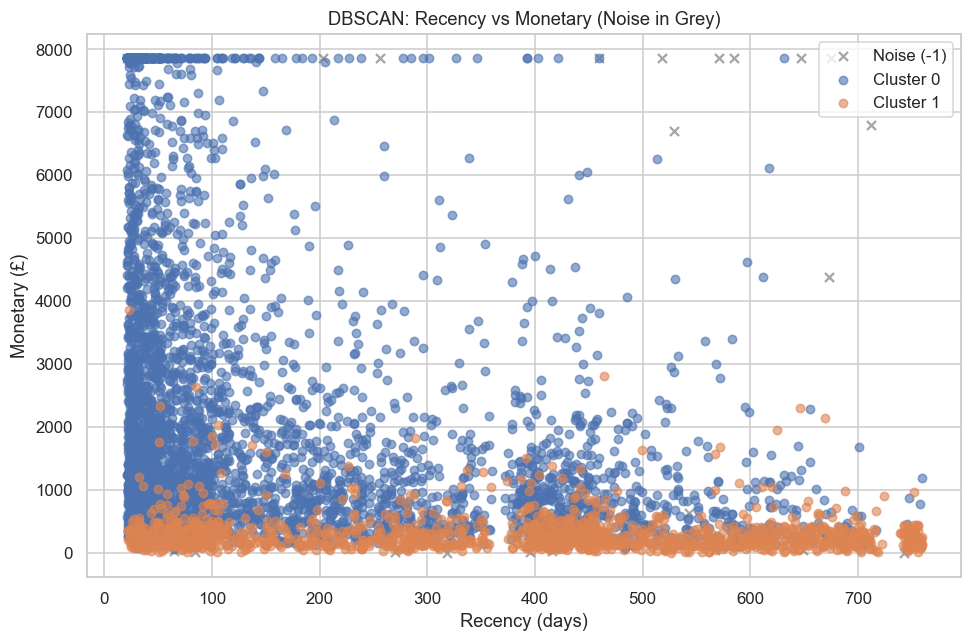

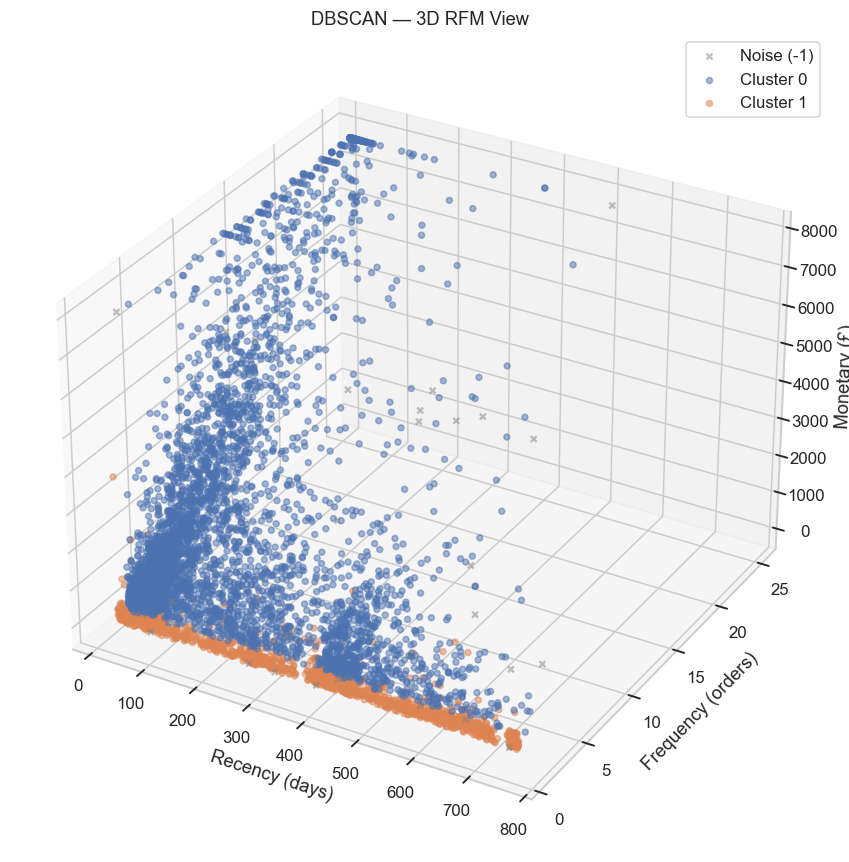

,Recency,Frequency,Monetary,CustomerCount,Persona
DBSCAN_Cluster,,,,,
0,163.05,7.1,2317.00,3859,At-Risk Loyal Customers
1,378.87,1.0,302.38,1465,Hibernating / Low Activity


Average RFM values for noise customers:


,NoiseAverage
Recency,450.04
Frequency,4.15
Monetary,3469.39


In [24]:
dbscan_model = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')
dbscan_labels = dbscan_model.fit_predict(rfm_scaled)
rfm_results['DBSCAN_Cluster'] = dbscan_labels

final_dbscan_cluster_count = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
final_noise_count = int((dbscan_labels == -1).sum())
final_noise_pct = final_noise_count / len(dbscan_labels) * 100
print('Final DBSCAN clusters (excluding noise):', final_dbscan_cluster_count)
print('Noise customers:', final_noise_count)
print(f'Noise percentage: {final_noise_pct:.2f}%')

# 2D plot with noise shown in grey
plt.figure(figsize=(9, 6))
for label in sorted(np.unique(dbscan_labels)):
    subset = rfm_results[rfm_results['DBSCAN_Cluster'] == label]
    if label == -1:
        plt.scatter(subset['Recency'], subset['Monetary'], color='grey', marker='x', s=35, alpha=0.7, label='Noise (-1)')
    else:
        plt.scatter(subset['Recency'], subset['Monetary'], s=30, alpha=0.6, label=f'Cluster {label}')
plt.title('DBSCAN: Recency vs Monetary (Noise in Grey)')
plt.xlabel('Recency (days)')
plt.ylabel('Monetary (£)')
plt.legend()
plt.tight_layout()
plt.show()

# 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
for label in sorted(np.unique(dbscan_labels)):
    subset = rfm_results[rfm_results['DBSCAN_Cluster'] == label]
    if label == -1:
        ax.scatter(subset['Recency'], subset['Frequency'], subset['Monetary'], color='grey', marker='x', s=15, alpha=0.5, label='Noise (-1)')
    else:
        ax.scatter(subset['Recency'], subset['Frequency'], subset['Monetary'], s=15, alpha=0.5, label=f'Cluster {label}')
ax.set_title('DBSCAN — 3D RFM View')
ax.set_xlabel('Recency (days)')
ax.set_ylabel('Frequency (orders)')
ax.set_zlabel('Monetary (£)')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

dbscan_profile = rfm_results[rfm_results['DBSCAN_Cluster'] != -1].groupby('DBSCAN_Cluster')[rfm_features].mean()
dbscan_profile['CustomerCount'] = rfm_results[rfm_results['DBSCAN_Cluster'] != -1].groupby('DBSCAN_Cluster').size()
dbscan_profile['Persona'] = dbscan_profile.apply(lambda row: rfm_persona(row, rfm_medians['Recency'], rfm_medians['Frequency'], rfm_medians['Monetary']), axis=1)
display(dbscan_profile.sort_values('Monetary', ascending=False).round(2))

noise_profile = rfm_results[rfm_results['DBSCAN_Cluster'] == -1][rfm_features].mean()
print('Average RFM values for noise customers:')
display(noise_profile.to_frame('NoiseAverage').round(2))

## 📊 Step 6 — Algorithm Comparison & Business Interpretation

Each algorithm has a different way of forming groups. I will compare the internal metrics on the same scaled feature space. Silhouette is higher when clusters are more separated, Davies–Bouldin is lower when clusters are compact and separated, and Calinski–Harabasz is higher when between-cluster separation is strong relative to within-cluster variation. These metrics are evidence, not a substitute for checking whether the segments make sense to the business.

### 6.1 Internal Metrics Comparison

For DBSCAN, the metrics are calculated on non-noise points when it produces at least two clusters. The noise percentage is reported separately. K-Means and Agglomerative clustering assign every customer to a cluster, so their noise percentage is 0%.

In [25]:
def calculate_metrics(name, labels, parameters, noise_label=None):
    labels = np.asarray(labels)
    if noise_label is None:
        evaluation_mask = np.ones(len(labels), dtype=bool)
        noise_percent = 0.0
    else:
        evaluation_mask = labels != noise_label
        noise_percent = (labels == noise_label).mean() * 100
    eval_labels = labels[evaluation_mask]
    eval_data = rfm_scaled[evaluation_mask]
    n_clusters = len(set(eval_labels))
    if n_clusters >= 2 and len(eval_labels) > n_clusters:
        silhouette = silhouette_score(eval_data, eval_labels, sample_size=min(10000, len(eval_labels)), random_state=42) if len(eval_labels) > 10000 else silhouette_score(eval_data, eval_labels)
        db_index = davies_bouldin_score(eval_data, eval_labels)
        ch_index = calinski_harabasz_score(eval_data, eval_labels)
    else:
        silhouette, db_index, ch_index = np.nan, np.nan, np.nan
    return {'Algorithm': name, 'Hyperparameters': parameters, 'Clusters': n_clusters, 'Silhouette': silhouette, 'DaviesBouldin': db_index, 'CalinskiHarabasz': ch_index, 'NoisePercent': noise_percent}

comparison_rows = [
    calculate_metrics('K-Means', kmeans_labels, f'k={k_optimal}, n_init=20, max_iter=500'),
    calculate_metrics('Agglomerative', agg_labels, f'n_clusters={chosen_hierarchical_k}, linkage={best_linkage}'),
    calculate_metrics('DBSCAN', dbscan_labels, f'eps={best_eps}, min_samples={best_min_samples}', noise_label=-1)
]
metrics_comparison = pd.DataFrame(comparison_rows)
display(metrics_comparison.round(4))
print('Use all metrics plus cluster profiles and stability to form the final recommendation; no single metric should decide deployment.')

,Algorithm,Hyperparameters,Clusters,Silhouette,DaviesBouldin,CalinskiHarabasz,NoisePercent
0,K-Means,"k=2, n_init=20, max_iter=500",2,0.4331,0.8662,5880.0835,0.000
1,Agglomerative,"n_clusters=3, linkage=ward",3,0.3859,0.9176,5524.0802,0.000
2,DBSCAN,"eps=0.5, min_samples=5",2,0.3335,1.0272,3121.3716,0.486


Use all metrics plus cluster profiles and stability to form the final recommendation; no single metric should decide deployment.


### 6.2 K-Means Stability Check

I will repeat K-Means five times using the exam’s random states. I will keep the chosen number of clusters fixed and compare the silhouette scores. A small standard deviation suggests that the quality score is not changing much across these initializations.

In [26]:
stability_random_states = [0, 7, 21, 42, 99]
stability_rows = []
for state in stability_random_states:
    stability_model = KMeans(n_clusters=k_optimal, init='k-means++', n_init=20, max_iter=500, random_state=state)
    stability_labels = stability_model.fit_predict(rfm_scaled)
    stability_rows.append({'RandomState': state, 'Silhouette': silhouette_score(rfm_scaled, stability_labels)})
stability_df = pd.DataFrame(stability_rows)
display(stability_df)
stability_mean = stability_df['Silhouette'].mean()
stability_std = stability_df['Silhouette'].std(ddof=1)
print(f'Silhouette mean ± standard deviation: {stability_mean:.4f} ± {stability_std:.4f}')

,RandomState,Silhouette
0,0,0.433091
1,7,0.433091
2,21,0.433091
3,42,0.433091
4,99,0.433091


Silhouette mean ± standard deviation: 0.4331 ± 0.0000


### 6.3 Business Recommendation to the Marketing Director

The recommendation below is built from the model comparison and the observed cluster profiles. It should be reviewed before any campaign is launched. Customer segmentation is a useful starting point for testing targeted messages, not a guarantee that a campaign will improve conversion.

In [27]:
# Helper to build a concise profile table from each algorithm's final labels
def persona_summary(profile, label_column):
    summary = profile.copy()
    return summary

print('K-Means customer personas:')
display(kmeans_profile.round(2))
print('Hierarchical customer personas:')
display(agg_profile.round(2))
print('DBSCAN customer personas (noise excluded):')
display(dbscan_profile.round(2))

# A metrics-based starting recommendation (can be reviewed alongside profile usefulness)
valid_metrics = metrics_comparison.dropna(subset=['Silhouette'])
metric_leader = valid_metrics.sort_values('Silhouette', ascending=False).iloc[0]['Algorithm'] if len(valid_metrics) else 'K-Means'
print('Highest silhouette among evaluated algorithms:', metric_leader)
print('Final deployment decision should also consider customer coverage, noise rate, stability, and whether marketing can act on the segments.')

K-Means customer personas:


,Recency,Frequency,Monetary,CustomerCount,Persona
KMeans_Cluster,,,,,
1,90.49,9.47,3219.12,2523,Champions / VIPs
0,342.30,1.80,478.47,2827,Hibernating / Low Activity


Hierarchical customer personas:


,Recency,Frequency,Monetary,CustomerCount,Persona
Agg_Cluster,,,,,
1,77.81,12.91,4498.76,1488,Champions / VIPs
2,109.34,2.99,824.22,2110,Recent / New Customers
0,484.86,1.97,594.30,1752,Hibernating / Low Activity


DBSCAN customer personas (noise excluded):


,Recency,Frequency,Monetary,CustomerCount,Persona
DBSCAN_Cluster,,,,,
0,163.05,7.1,2317.00,3859,At-Risk Loyal Customers
1,378.87,1.0,302.38,1465,Hibernating / Low Activity


Highest silhouette among evaluated algorithms: K-Means
Final deployment decision should also consider customer coverage, noise rate, stability, and whether marketing can act on the segments.


### 📣 Business Recommendation to the Marketing Director

**To:** Marketing Director, Flipkart/Meesho-style e-commerce business  
**Subject:** Recommended first customer segmentation pilot

Based on the model comparison, I recommend starting with **K-Means (K = 2)** for the first pilot. In this run it had the strongest silhouette score (**0.4331**), the lowest Davies–Bouldin index (**0.8662**) and the highest Calinski–Harabasz index (**5880.08**) among the three evaluated models. Its five-run silhouette stability check was also consistent (**0.4331 ± 0.0000**). It is a simple model to explain and it assigns every customer to a segment, which makes it a practical starting point. I would still validate the campaign results through an A/B test before wider deployment.

The two K-Means segments are:

- **Champions / VIPs (Cluster 1):** 2,523 customers; average Recency 90.49 days, Frequency 9.47 orders and Monetary £3,219.12. These customers are relatively recent, frequent and high-spending. I would test loyalty rewards, early access to new products and personalized cross-sell recommendations rather than automatically giving them large discounts.
- **Hibernating / Low Activity (Cluster 0):** 2,827 customers; average Recency 342.30 days, Frequency 1.80 orders and Monetary £478.47. These customers have not purchased recently and have lower order activity and spend. I would test a low-cost reactivation email with a limited-time offer, while reducing campaign frequency for customers who do not engage.

For a future version, I would add product-category preferences, discount usage, average basket size, email/app engagement, returns, delivery experience and customer tenure. These details could separate customers who look similar under RFM but have different preferences. Finally, I would run an A/B test by segment and measure conversion, revenue per customer, campaign cost and unsubscribe rate. The clusters are a useful starting hypothesis—not a guarantee that marketing actions will work.

## 🚀 Step 7 — Pipeline, Deployment & GitHub Submission

The exam requires the scaler and best clustering model to be saved with joblib. The scaler is important because new customers must be transformed using the same preprocessing that was used during training. For a deployment-ready workflow, the selected model should match the algorithm recommendation; below I save the K-Means model as a reproducible baseline and also save the selected comparison model if applicable.

In [28]:
# Select the model with the highest silhouette score in the comparison, using K-Means as fallback
metric_leader = metrics_comparison.sort_values('Silhouette', ascending=False).iloc[0]['Algorithm']
model_lookup = {'K-Means': kmeans_model, 'Agglomerative': agg_model, 'DBSCAN': dbscan_model}
best_model = model_lookup[metric_leader]

# Save the fitted scaler and selected clustering model using the exam-required filenames
joblib.dump(scaler, 'rfm_scaler.pkl')
joblib.dump(best_model, 'customer_segmentation_model.pkl')
print(f'Saved scaler and selected model: {metric_leader}')

# Save analysis tables for review
rfm_results.to_csv('customer_rfm_clusters.csv', index=False)
metrics_comparison.to_csv('algorithm_metrics_comparison.csv', index=False)
print('Saved customer_rfm_clusters.csv and algorithm_metrics_comparison.csv')

Saved scaler and selected model: K-Means
Saved customer_rfm_clusters.csv and algorithm_metrics_comparison.csv


### 7.1.1 Predicting a Segment for a New Customer

The exam asks us to test the saved model on five hypothetical customers. I will use the same preprocessing steps that were applied during training: cap Frequency and Monetary using the training thresholds, apply `log1p` to those two features, and use the fitted scaler. Because K-Means is the recommended model in this run, it can assign a cluster to new customers using `predict()`.

This is a small demonstration with hypothetical values—not real customer predictions.

In [29]:
# Persona lookup based on the actual K-Means cluster profiles
kmeans_persona_map = {
    cluster_id: persona
    for cluster_id, persona in kmeans_profile['Persona'].items()
}

def predict_segment(recency, frequency, monetary):
    """Return the K-Means cluster and persona for a new customer's raw RFM values."""
    new_customer = pd.DataFrame([{
        'Recency': recency,
        'Frequency': frequency,
        'Monetary': monetary
    }])

    # Apply the same upper-cap thresholds used during model training
    for feature in rfm_features:
        new_customer[feature] = new_customer[feature].clip(upper=cap_limits[feature])

    # Match the feature engineering used before scaling
    new_customer['Frequency_log'] = np.log1p(new_customer['Frequency'])
    new_customer['Monetary_log'] = np.log1p(new_customer['Monetary'])

    model_input = new_customer[scaling_features]
    scaled_input = scaler.transform(model_input)
    cluster = int(kmeans_model.predict(scaled_input)[0])
    persona = kmeans_persona_map.get(cluster, 'Persona not available')
    return cluster, persona

# Five hypothetical customer profiles to test the function
hypothetical_customers = pd.DataFrame([
    {'Customer': 'Customer A', 'Recency': 15, 'Frequency': 25, 'Monetary': 8500},
    {'Customer': 'Customer B', 'Recency': 45, 'Frequency': 12, 'Monetary': 3200},
    {'Customer': 'Customer C', 'Recency': 180, 'Frequency': 3, 'Monetary': 650},
    {'Customer': 'Customer D', 'Recency': 365, 'Frequency': 1, 'Monetary': 120},
    {'Customer': 'Customer E', 'Recency': 90, 'Frequency': 7, 'Monetary': 1800},
])

prediction_rows = []
for row in hypothetical_customers.itertuples(index=False):
    cluster, persona = predict_segment(row.Recency, row.Frequency, row.Monetary)
    prediction_rows.append({
        'Customer': row.Customer,
        'Recency': row.Recency,
        'Frequency': row.Frequency,
        'Monetary': row.Monetary,
        'PredictedCluster': cluster,
        'PredictedPersona': persona
    })

predictions_df = pd.DataFrame(prediction_rows)
display(predictions_df)
print('Prediction function tested on five hypothetical customers.')

,Customer,Recency,Frequency,Monetary,PredictedCluster,PredictedPersona
0,Customer A,15,25,8500,1,Champions / VIPs
1,Customer B,45,12,3200,1,Champions / VIPs
2,Customer C,180,3,650,0,Hibernating / Low Activity
3,Customer D,365,1,120,0,Hibernating / Low Activity
4,Customer E,90,7,1800,1,Champions / VIPs


Prediction function tested on five hypothetical customers.


In [30]:
# Create a requirements file for the project environment
requirements = [
    'pandas', 'numpy', 'matplotlib', 'seaborn', 'scikit-learn',
    'scipy', 'plotly', 'joblib'
]
with open('requirements.txt', 'w', encoding='utf-8') as file:
    file.write('\n'.join(requirements) + '\n')
print('requirements.txt created')

requirements.txt created


## 🧾 Final Project Checklist

- [ ] Dataset loaded and its structure inspected
- [ ] UK-only filtering and cleaning counts reported
- [ ] EDA plots completed
- [ ] Customer spend and frequency analysis completed
- [ ] RFM table built with the exam reference date
- [ ] Outliers capped using Q3 + 3×IQR
- [ ] Frequency and Monetary log-transformed
- [ ] Features scaled with StandardScaler
- [ ] K-Means elbow and silhouette plots shown
- [ ] K-Means visualizations and profiles completed
- [ ] Hierarchical dendrogram and linkage comparison completed
- [ ] DBSCAN k-NN plot, tuning heatmap, cluster/noise analysis completed
- [ ] Internal metrics comparison table completed
- [ ] K-Means stability check completed
- [ ] Business recommendation reviewed against actual outputs
- [ ] Scaler and model saved\n- [ ] predict_segment() tested on five hypothetical customers
- [ ] Summary report is 400–500 words\n- [ ] README includes dataset link, setup, personas, and video link placeholder\n- [ ] Public GitHub repository created with the required name\n- [ ] Summary report, README, requirements and video prepared
- [ ] Notebook restarted and run from top to bottom with no errors

## 🎓 Final Reflection

This project helped me move from raw transaction records to customer-level behaviour patterns. I learned that the algorithm labels themselves are not meaningful until I profile the customers in each group and connect the results to a business decision. I also learned that clustering quality needs more than one metric: I should consider separation, compactness, stability, noise, and whether the segments are practical to use. The next step would be to validate the proposed campaigns with an A/B test rather than assuming the clusters automatically improve sales.